In [3]:
!pip -q install torch torchvision matplotlib pillow scikit-image tqdm

import os
import glob
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.transforms import functional as TF

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

ROOT = Path("/content/cmp_facades")
ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", ROOT)

Device: cuda
Dataset directory: /content/cmp_facades


In [4]:
DATASETS = {
    "base": (
        "https://cmp.felk.cvut.cz/~tylecr1/facade/"
        "CMP_facade_DB_base.zip"
    ),
    "extended": (
        "https://cmp.felk.cvut.cz/~tylecr1/facade/"
        "CMP_facade_DB_extended.zip"
    ),
}

for name, url in DATASETS.items():
    archive = ROOT / f"{name}.zip"
    extract_dir = ROOT / name

    if not archive.exists():
        print(f"Downloading {name} dataset...")
        urllib.request.urlretrieve(url, archive)

    if not extract_dir.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(extract_dir)

    print(f"{name}: ready at {extract_dir}")

print("Download and extraction completed.")

base: ready at /content/cmp_facades/base
extended: ready at /content/cmp_facades/extended
Download and extraction completed.


In [5]:
IMAGE_EXTS = {".jpg", ".jpeg"}
LABEL_EXTS = {".png"}

all_files = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS | LABEL_EXTS
]

print("Total JPG/JPEG/PNG files:", len(all_files))
print("\nExample paths:")
for p in all_files[:30]:
    print(p.relative_to(ROOT))

jpg_files = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]
png_files = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in LABEL_EXTS
]

print("\nJPEG images:", len(jpg_files))
print("PNG files:", len(png_files))

Total JPG/JPEG/PNG files: 1212

Example paths:
base/base/cmp_b0081.jpg
base/base/cmp_b0211.png
base/base/cmp_b0212.jpg
base/base/cmp_b0302.jpg
base/base/cmp_b0305.jpg
base/base/cmp_b0373.jpg
base/base/cmp_b0282.jpg
base/base/cmp_b0273.jpg
base/base/cmp_b0060.png
base/base/cmp_b0075.jpg
base/base/cmp_b0322.jpg
base/base/cmp_b0338.jpg
base/base/cmp_b0002.png
base/base/cmp_b0235.jpg
base/base/cmp_b0104.png
base/base/cmp_b0239.jpg
base/base/cmp_b0160.jpg
base/base/cmp_b0094.jpg
base/base/cmp_b0329.jpg
base/base/cmp_b0359.jpg
base/base/cmp_b0218.jpg
base/base/cmp_b0228.jpg
base/base/cmp_b0161.jpg
base/base/cmp_b0278.jpg
base/base/cmp_b0082.png
base/base/cmp_b0175.png
base/base/cmp_b0128.png
base/base/cmp_b0048.jpg
base/base/cmp_b0311.jpg
base/base/cmp_b0340.png

JPEG images: 606
PNG files: 606


In [6]:
from collections import defaultdict

png_by_stem = defaultdict(list)

for p in png_files:
    png_by_stem[p.stem.lower()].append(p)

pairs = []
unmatched_images = []

for photo_path in jpg_files:
    candidates = png_by_stem.get(photo_path.stem.lower(), [])

    # Prefer PNGs whose path suggests pixelwise/color labels.
    preferred = [
        p for p in candidates
        if any(word in str(p.parent).lower()
               for word in ["label", "annotation", "pixel"])
    ]

    if len(preferred) == 1:
        pairs.append((photo_path, preferred[0]))
    elif len(candidates) == 1:
        pairs.append((photo_path, candidates[0]))
    else:
        unmatched_images.append(photo_path)

print("Matched photo-label pairs:", len(pairs))
print("Unmatched photographs:", len(unmatched_images))

for photo, label in pairs[:10]:
    print("PHOTO:", photo.relative_to(ROOT))
    print("LABEL:", label.relative_to(ROOT))
    print("---")

if unmatched_images:
    print("\nFirst unmatched photographs:")
    for p in unmatched_images[:15]:
        print(p.relative_to(ROOT))

Matched photo-label pairs: 606
Unmatched photographs: 0
PHOTO: base/base/cmp_b0081.jpg
LABEL: base/base/cmp_b0081.png
---
PHOTO: base/base/cmp_b0212.jpg
LABEL: base/base/cmp_b0212.png
---
PHOTO: base/base/cmp_b0302.jpg
LABEL: base/base/cmp_b0302.png
---
PHOTO: base/base/cmp_b0305.jpg
LABEL: base/base/cmp_b0305.png
---
PHOTO: base/base/cmp_b0373.jpg
LABEL: base/base/cmp_b0373.png
---
PHOTO: base/base/cmp_b0282.jpg
LABEL: base/base/cmp_b0282.png
---
PHOTO: base/base/cmp_b0273.jpg
LABEL: base/base/cmp_b0273.png
---
PHOTO: base/base/cmp_b0075.jpg
LABEL: base/base/cmp_b0075.png
---
PHOTO: base/base/cmp_b0322.jpg
LABEL: base/base/cmp_b0322.png
---
PHOTO: base/base/cmp_b0338.jpg
LABEL: base/base/cmp_b0338.png
---


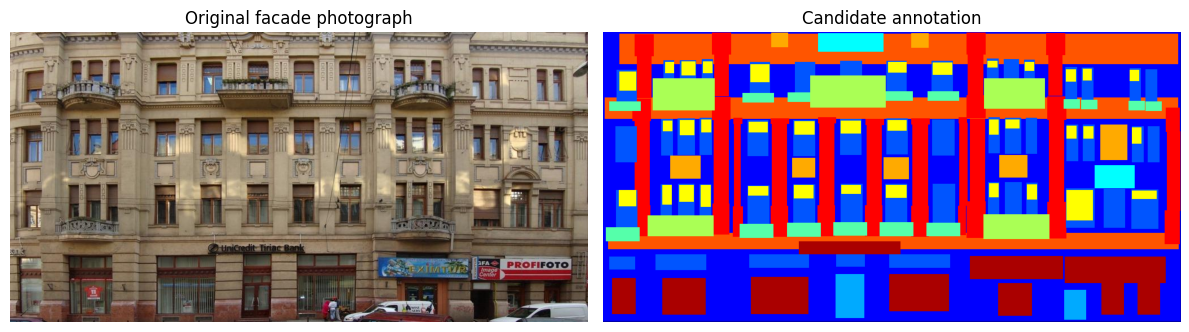

Photo: cmp_b0081.jpg (1024, 514)
Label: cmp_b0081.png (1024, 514)
Label mode: P
Label dimensions: (1024, 514)


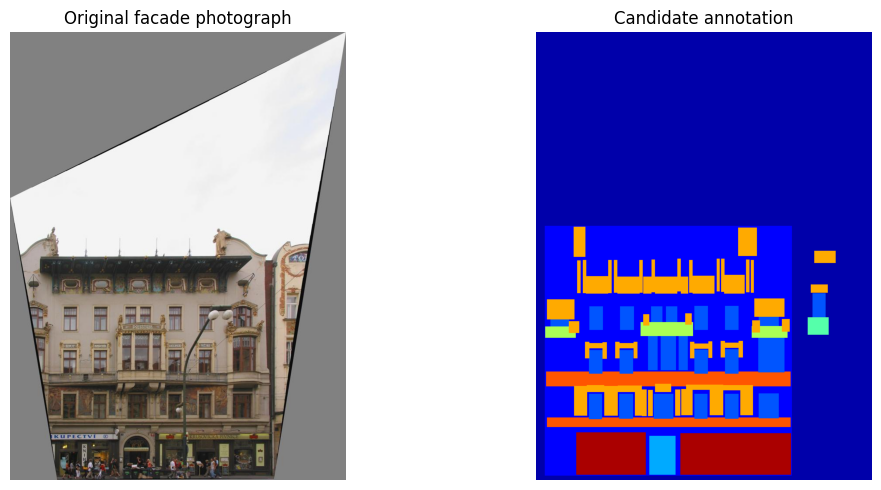

Photo: cmp_b0212.jpg (768, 1024)
Label: cmp_b0212.png (768, 1024)
Label mode: P
Label dimensions: (768, 1024)


In [7]:
assert len(pairs) > 0, (
    "No matching photo-label pairs found. "
    "Inspect the filenames and folder structure."
)

def inspect_pair(index):
    photo_path, label_path = pairs[index]

    photo = Image.open(photo_path).convert("RGB")
    label = Image.open(label_path)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].imshow(photo)
    ax[0].set_title("Original facade photograph")

    ax[1].imshow(label)
    ax[1].set_title("Candidate annotation")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

    print("Photo:", photo_path.name, photo.size)
    print("Label:", label_path.name, label.size)
    print("Label mode:", label.mode)
    print("Label dimensions:", label.size)

inspect_pair(0)
if len(pairs) > 1:
    inspect_pair(1)

In [8]:
from torch.utils.data import Subset

class CMPFacadeDataset(Dataset):
    def __init__(self, pairs, augment=False, size=256):
        self.pairs = pairs
        self.augment = augment
        self.size = size

        self.to_tensor = transforms.Compose([
            transforms.Resize(
                (size, size),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5),
                                 (0.5, 0.5, 0.5))
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        photo_path, label_path = self.pairs[idx]

        # Input = semantic annotation; target = real facade photograph
        source = Image.open(label_path).convert("RGB")
        target = Image.open(photo_path).convert("RGB")

        # Verify original dimensions match before resizing
        if source.size != target.size:
            raise ValueError(
                f"Dimension mismatch: {label_path.name} {source.size} "
                f"vs {photo_path.name} {target.size}"
            )

        if self.augment and torch.rand(1).item() < 0.5:
            source = TF.hflip(source)
            target = TF.hflip(target)

        source = self.to_tensor(source)
        target = self.to_tensor(target)

        return source, target

dataset = CMPFacadeDataset(pairs, augment=False)

n = len(dataset)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset, test_subset = random_split(
    dataset, [n_train, n_val, n_test], generator=generator
)

# Training augmentation is applied only to the training subset.
train_dataset = CMPFacadeDataset(pairs, augment=True)

train_dataset = Subset(
    train_dataset, train_subset.indices
)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_subset, batch_size=1, shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_subset, batch_size=1, shuffle=False, num_workers=2
)

print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_subset)}")
print(f"Test: {len(test_subset)}")

Train: 484
Validation: 60
Test: 62


In [9]:
import torch.nn as nn

def down_block(in_c, out_c, norm=True):
    layers = [nn.Conv2d(in_c, out_c, 4, 2, 1,
                        bias=not norm)]
    if norm:
        layers.append(nn.BatchNorm2d(out_c))
    layers.append(nn.LeakyReLU(0.2, inplace=True))
    return nn.Sequential(*layers)

def up_block(in_c, out_c, dropout=False):
    layers = [
        nn.ConvTranspose2d(in_c, out_c, 4, 2, 1, bias=False),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True)
    ]
    if dropout:
        layers.append(nn.Dropout(0.5))
    return nn.Sequential(*layers)

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.d1 = down_block(3, 64, False)
        self.d2 = down_block(64, 128)
        self.d3 = down_block(128, 256)
        self.d4 = down_block(256, 512)
        self.d5 = down_block(512, 512)
        self.d6 = down_block(512, 512)
        self.d7 = down_block(512, 512)
        self.d8 = down_block(512, 512, False)

        self.u1 = up_block(512, 512, True)
        self.u2 = up_block(1024, 512, True)
        self.u3 = up_block(1024, 512, True)
        self.u4 = up_block(1024, 512)
        self.u5 = up_block(1024, 256)
        self.u6 = up_block(512, 128)
        self.u7 = up_block(256, 64)
        self.out = nn.Sequential(
            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        d8 = self.d8(d7)

        x = torch.cat([self.u1(d8), d7], 1)
        x = torch.cat([self.u2(x), d6], 1)
        x = torch.cat([self.u3(x), d5], 1)
        x = torch.cat([self.u4(x), d4], 1)
        x = torch.cat([self.u5(x), d3], 1)
        x = torch.cat([self.u6(x), d2], 1)
        x = torch.cat([self.u7(x), d1], 1)
        return self.out(x)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(6, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 1, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 1)
        )

    def forward(self, source, target):
        return self.net(torch.cat([source, target], dim=1))

G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)

with torch.no_grad():
    x = torch.randn(1, 3, 256, 256, device=DEVICE)
    y = G(x)
    print("Generator output:", y.shape)

assert y.shape == (1, 3, 256, 256)

Generator output: torch.Size([1, 3, 256, 256])


Epoch 1/30:   0%|          | 0/121 [00:00<?, ?it/s]

Epoch 1: G=43.227, D=0.350, Val L1=0.4004


Epoch 2/30:   0%|          | 0/121 [00:00<?, ?it/s]

Epoch 2: G=41.021, D=0.228, Val L1=0.3900


Epoch 3/30:   0%|          | 0/121 [00:00<?, ?it/s]

...

Epoch 28: G=33.235, D=0.401, Val L1=0.4187


Epoch 29/30:   0%|          | 0/121 [00:00<?, ?it/s]

Epoch 29: G=32.546, D=0.374, Val L1=0.4014


Epoch 30/30:   0%|          | 0/121 [00:00<?, ?it/s]

Epoch 30: G=32.321, D=0.423, Val L1=0.4031


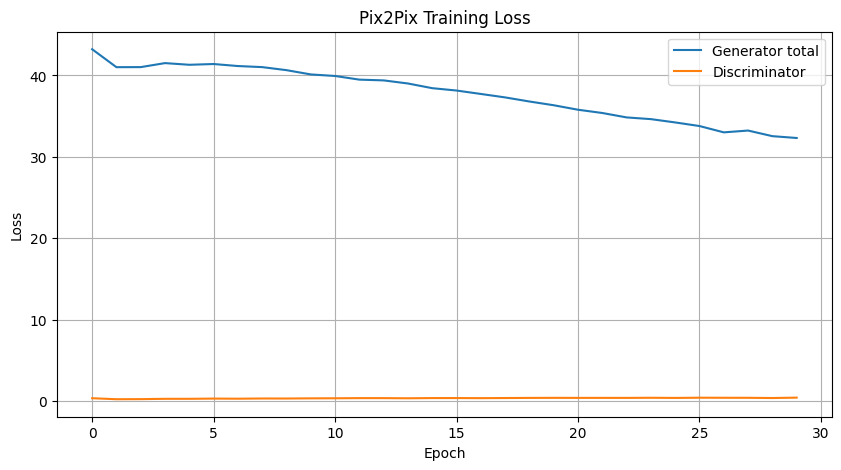

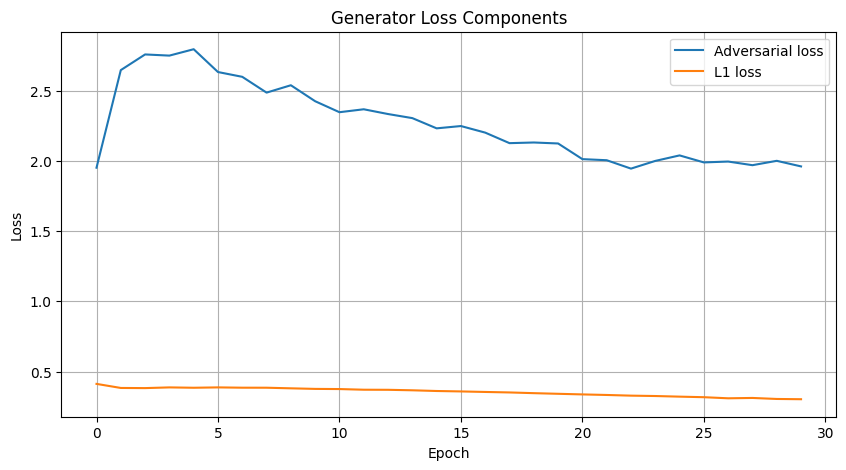

Training completed. Outputs: /content/cmp_project_outputs


In [10]:
import json
from tqdm.auto import tqdm

criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1 = nn.L1Loss()

optimizer_G = torch.optim.Adam(
    G.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
optimizer_D = torch.optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

LAMBDA_L1 = 100
EPOCHS = 30

OUT = Path("/content/cmp_project_outputs")
(OUT / "generated_facades").mkdir(parents=True, exist_ok=True)

history = {"G": [], "D": [], "G_adv": [], "G_L1": []}
best_val_l1 = float("inf")

def evaluate_l1(model, loader):
    model.eval()
    total, count = 0.0, 0

    with torch.no_grad():
        for source, target in loader:
            source, target = source.to(DEVICE), target.to(DEVICE)
            pred = model(source)
            total += criterion_l1(pred, target).item()
            count += 1

    return total / max(count, 1)

for epoch in range(EPOCHS):
    G.train()
    D.train()
    totals = {"G": 0.0, "D": 0.0, "G_adv": 0.0, "G_L1": 0.0}

    for source, target in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        source = source.to(DEVICE)
        target = target.to(DEVICE)

        # Train discriminator
        optimizer_D.zero_grad(set_to_none=True)

        with torch.no_grad():
            fake = G(source)

        pred_real = D(source, target)
        pred_fake = D(source, fake)

        loss_D = 0.5 * (
            criterion_gan(pred_real, torch.ones_like(pred_real)) +
            criterion_gan(pred_fake, torch.zeros_like(pred_fake))
        )
        loss_D.backward()
        optimizer_D.step()

        # Train generator
        optimizer_G.zero_grad(set_to_none=True)

        fake = G(source)
        pred_fake = D(source, fake)

        loss_adv = criterion_gan(
            pred_fake, torch.ones_like(pred_fake)
        )
        loss_l1 = criterion_l1(fake, target)
        loss_G = loss_adv + LAMBDA_L1 * loss_l1

        loss_G.backward()
        optimizer_G.step()

        totals["G"] += loss_G.item()
        totals["D"] += loss_D.item()
        totals["G_adv"] += loss_adv.item()
        totals["G_L1"] += loss_l1.item()

    for key in totals:
        history[key].append(totals[key] / len(train_loader))

    val_l1 = evaluate_l1(G, val_loader)

    print(
        f"Epoch {epoch+1}: "
        f"G={history['G'][-1]:.3f}, "
        f"D={history['D'][-1]:.3f}, "
        f"Val L1={val_l1:.4f}"
    )

    checkpoint = {
        "epoch": epoch + 1,
        "generator": G.state_dict(),
        "discriminator": D.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "history": history,
        "val_l1": val_l1
    }

    # Always save latest state for recovery
    torch.save(checkpoint, OUT / "latest_checkpoint.pth")

    # Save best generator based on validation L1
    if val_l1 < best_val_l1:
        best_val_l1 = val_l1
        torch.save(G.state_dict(), OUT / "best_generator.pth")

# Plot training losses
plt.figure(figsize=(10, 5))
plt.plot(history["G"], label="Generator total")
plt.plot(history["D"], label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pix2Pix Training Loss")
plt.legend()
plt.grid(True)
plt.savefig(OUT / "loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history["G_adv"], label="Adversarial loss")
plt.plot(history["G_L1"], label="L1 loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator Loss Components")
plt.legend()
plt.grid(True)
plt.show()

with open(OUT / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("Training completed. Outputs:", OUT)

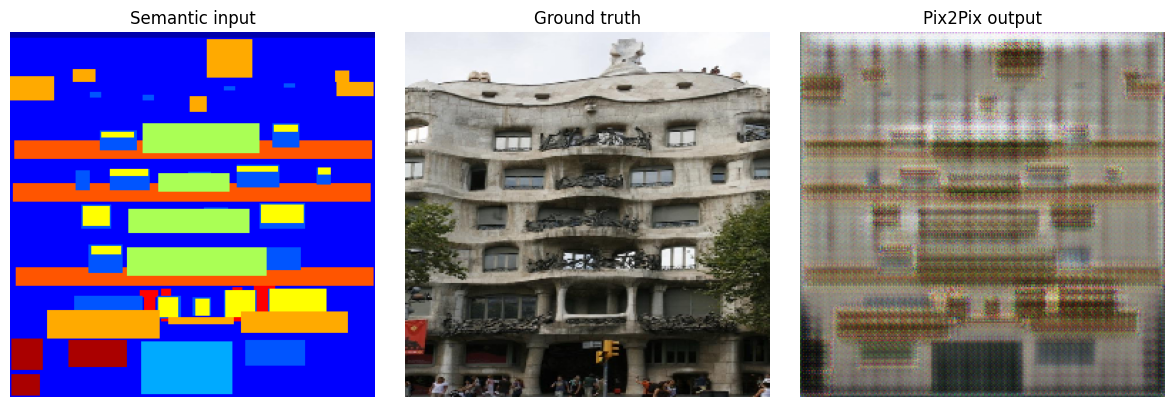

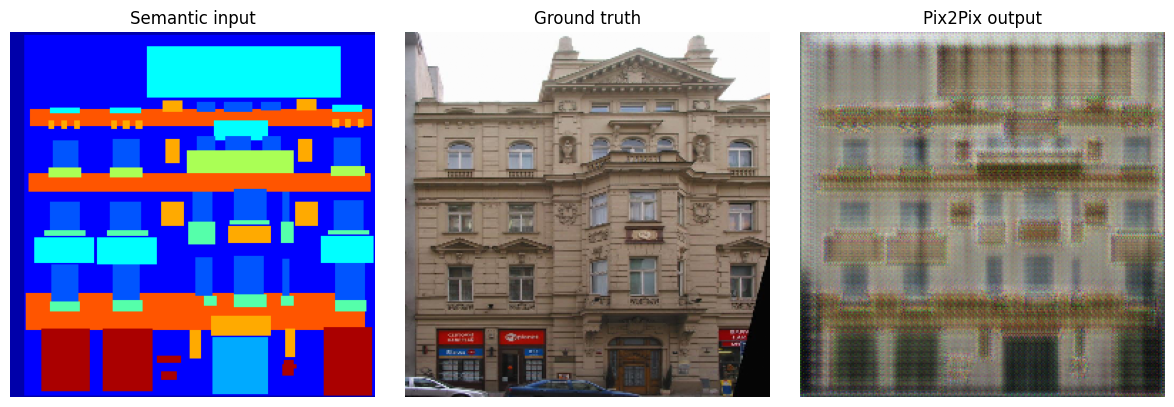

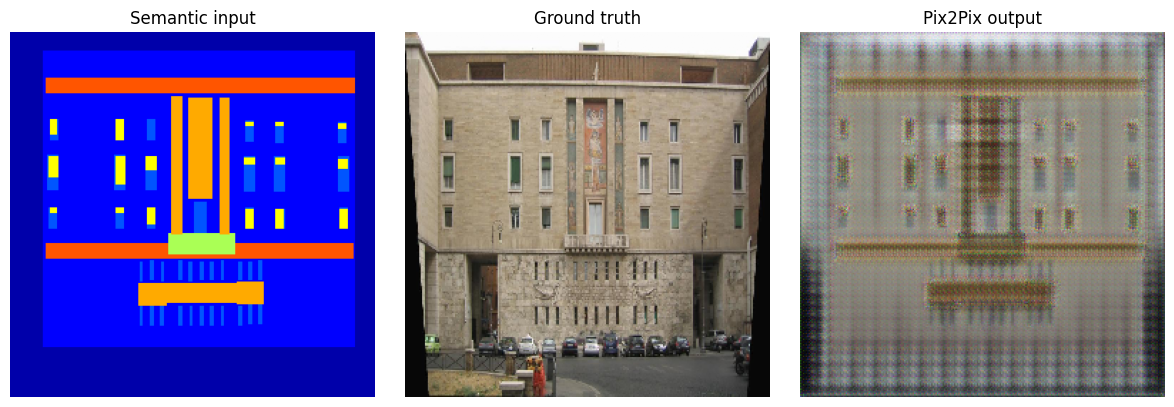

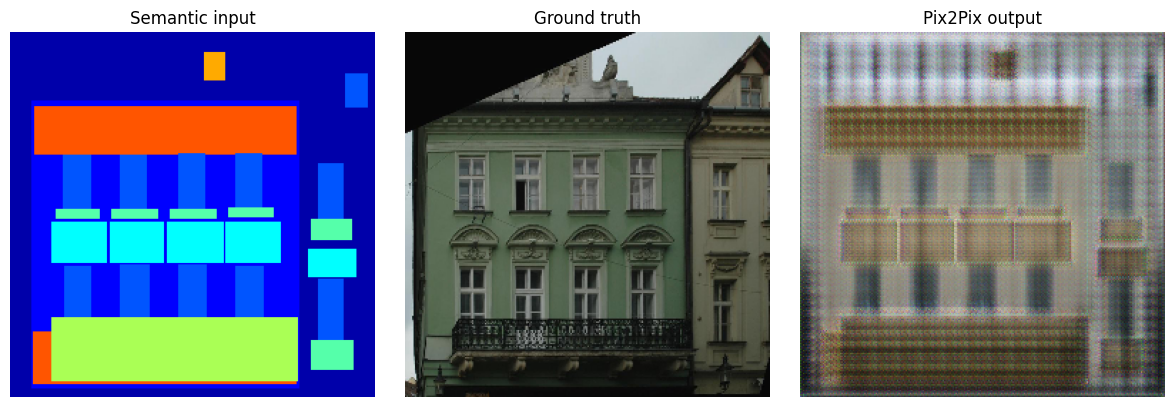

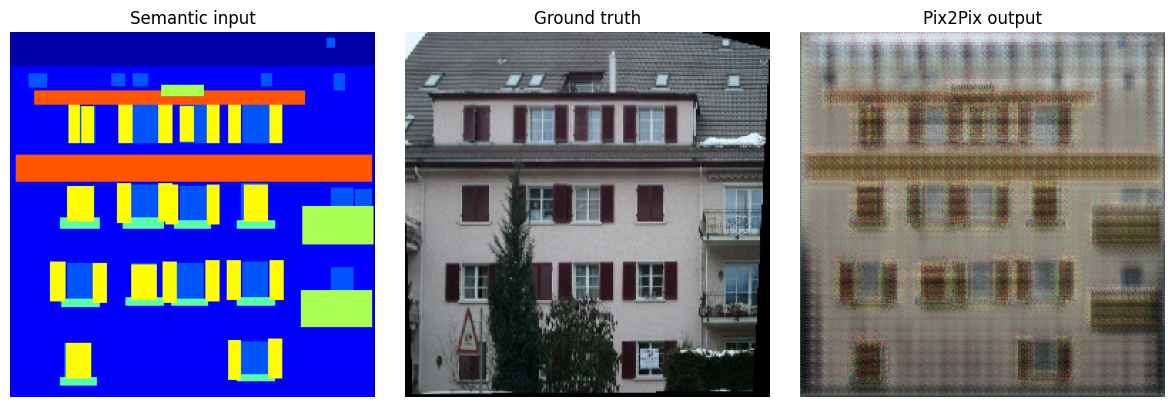

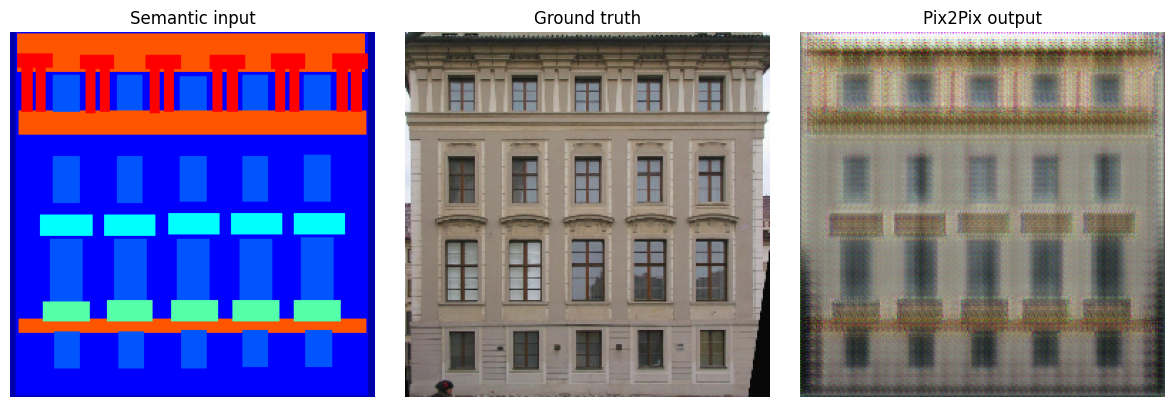

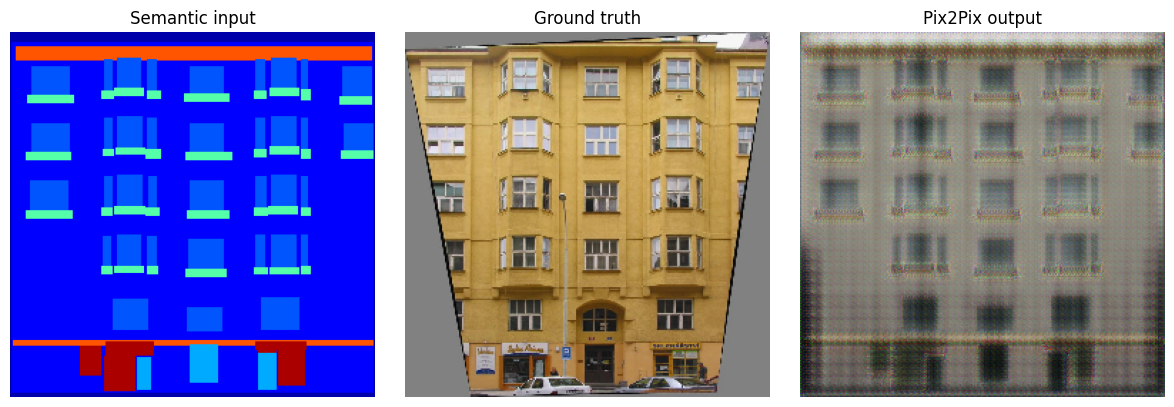

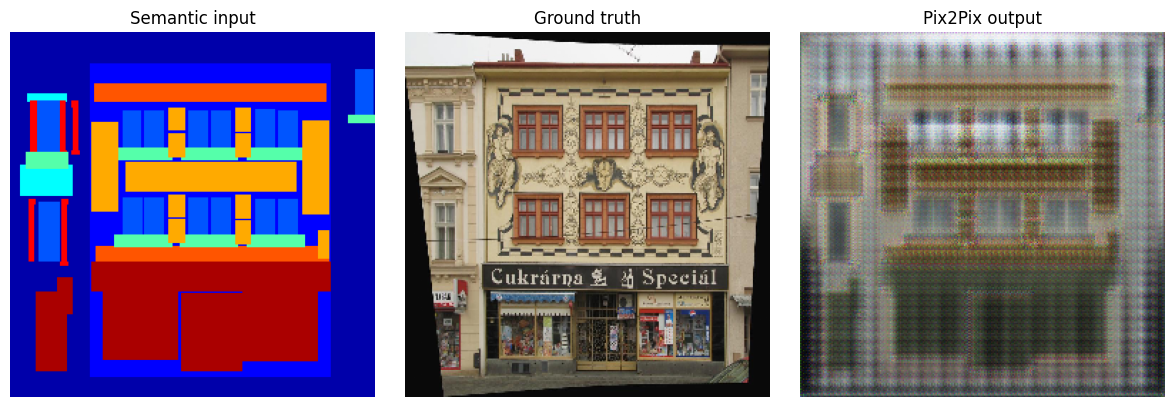

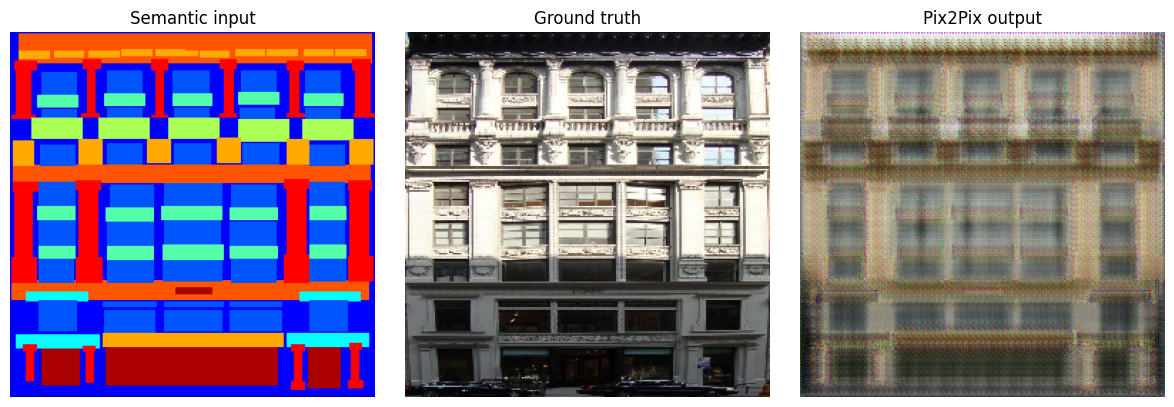

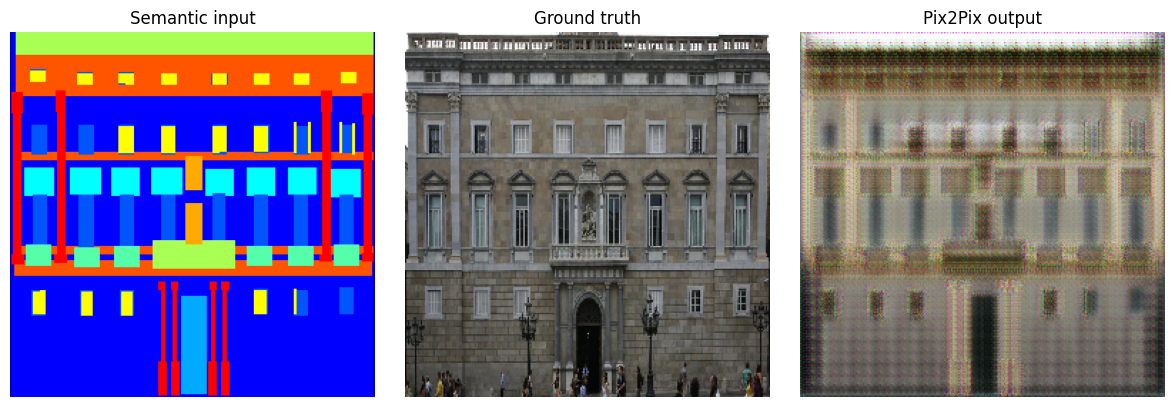

{
  "dataset": "CMP Facade Database",
  "model": "Pix2Pix conditional GAN",
  "test_samples": 62,
  "test_mae": 0.18718324613667303,
  "test_ssim": 0.14560396500652836,
  "best_validation_l1": 0.38999310781558355,
  "epochs_trained": 30
}


In [11]:
from skimage.metrics import structural_similarity as ssim

# Load the best validation checkpoint for final evaluation
best_path = OUT / "best_generator.pth"
G.load_state_dict(torch.load(best_path, map_location=DEVICE,
                             weights_only=True))
G.eval()

def to_image(tensor):
    return ((tensor.detach().cpu().permute(1, 2, 0).numpy() + 1) / 2).clip(0, 1)

mae_values, ssim_values = [], []
saved = 0

with torch.no_grad():
    for source, target in test_loader:
        source_device = source.to(DEVICE)
        target_device = target.to(DEVICE)
        pred = G(source_device)

        src_img = to_image(source[0])
        real_img = to_image(target[0])
        pred_img = to_image(pred[0])

        mae = float(np.mean(np.abs(pred_img - real_img)))
        score = float(ssim(
            real_img, pred_img, data_range=1.0, channel_axis=-1
        ))

        mae_values.append(mae)
        ssim_values.append(score)

        if saved < 10:
            fig, ax = plt.subplots(1, 3, figsize=(12, 4))

            for a, im, title in zip(
                ax,
                [src_img, real_img, pred_img],
                ["Semantic input", "Ground truth", "Pix2Pix output"]
            ):
                a.imshow(im)
                a.set_title(title)
                a.axis("off")

            plt.tight_layout()
            plt.savefig(
                OUT / "generated_facades" / f"comparison_{saved+1:02d}.png",
                dpi=150, bbox_inches="tight"
            )
            plt.show()
            saved += 1

test_results = {
    "dataset": "CMP Facade Database",
    "model": "Pix2Pix conditional GAN",
    "test_samples": len(mae_values),
    "test_mae": float(np.mean(mae_values)),
    "test_ssim": float(np.mean(ssim_values)),
    "best_validation_l1": float(best_val_l1),
    "epochs_trained": len(history["G"])
}

with open(OUT / "evaluation_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(json.dumps(test_results, indent=2))
